In [1]:
import pandas as pd
import numpy as np


In [2]:
ML_DATA=pd.read_csv("../data/feature_engineered_data.csv")
print(ML_DATA.head())

   UserID  ChargerID  ChargerCompany Location  ChargerType    StartDay  \
0       0          1               1    hotel            0  2022-09-15   
1       0          1               1    hotel            0  2022-09-14   
2       0          1               1    hotel            0  2022-09-14   
3       0          1               1    hotel            0  2022-09-29   
4       0          1               1    hotel            0  2022-09-25   

  StartTime      EndDay   EndTime        StartDatetime          EndDatetime  \
0  20:54:02  2022-09-15  23:59:13  2022-09-15 20:54:00  2022-09-15 23:59:00   
1  20:01:05  2022-09-14  21:31:04  2022-09-14 20:01:00  2022-09-14 21:31:00   
2  18:54:30  2022-09-14  19:54:29  2022-09-14 18:54:00  2022-09-14 19:54:00   
3  18:32:51  2022-09-30   0:16:42  2022-09-29 18:32:00  2022-09-30 00:16:00   
4  19:30:15  2022-09-26   0:30:14  2022-09-25 19:30:00  2022-09-26 00:30:00   

   Duration  Demand  StartHour  StartDayOfWeek  StartMonth  StartYear  \
0      

In [3]:
TARGET = "Demand"

In [4]:
drop_columns = [
    "Demand",
    "UserID",
    "ChargerID",
    "StartDatetime",
    "EndDatetime",
    "StartDay",
    "StartTime",
    "EndDay",
    "EndTime",
    "EndHour",
    "Duration"
]

In [5]:
X = ML_DATA.drop(
    columns=[col for col in drop_columns if col in ML_DATA.columns]
)

y = pd.to_numeric(ML_DATA[TARGET], errors="coerce")

# Remove rows with missing target
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("Features:", X.shape)
print("Target:", y.shape)

X.head()

Features: (72843, 9)
Target: (72843,)


,ChargerCompany,Location,ChargerType,StartHour,StartDayOfWeek,StartMonth,StartYear,IsWeekend,TimePeriod
0,1,hotel,0,20,3,9,2022,0,Evening
1,1,hotel,0,20,2,9,2022,0,Evening
2,1,hotel,0,18,2,9,2022,0,Evening
3,1,hotel,0,18,3,9,2022,0,Evening
4,1,hotel,0,19,6,9,2022,1,Evening


In [6]:
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['ChargerCompany', 'ChargerType', 'StartHour', 'StartDayOfWeek', 'StartMonth', 'StartYear', 'IsWeekend']

Categorical features:
['Location', 'TimePeriod']


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_8788\3080918941.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [7]:
from sklearn.model_selection import train_test_split


In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(58274, 9) (14569, 9) (58274,) (14569,)


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [11]:
#regression data preparation
X_train_reg = x_train.copy()
X_test_reg = x_test.copy()

y_train_reg = y_train.copy()
y_test_reg = y_test.copy()

print("Regression training:", X_train_reg.shape)
print("Regression testing:", X_test_reg.shape)

Regression training: (58274, 9)
Regression testing: (14569, 9)


In [12]:
#classification data preparation
# Create a binary target variable for classification
demand_threshold = y_train.median()

y_train_cls = (
    y_train >= demand_threshold
).astype(int)

y_test_cls = (
    y_test >= demand_threshold
).astype(int)

print("Demand threshold:", demand_threshold)

print("\nTraining class distribution:")
print(y_train_cls.value_counts())

print("\nTesting class distribution:")
print(y_test_cls.value_counts())

Demand threshold: 14.114999999999998

Training class distribution:
Demand
1    29137
0    29137
Name: count, dtype: int64

Testing class distribution:
Demand
0    7321
1    7248
Name: count, dtype: int64


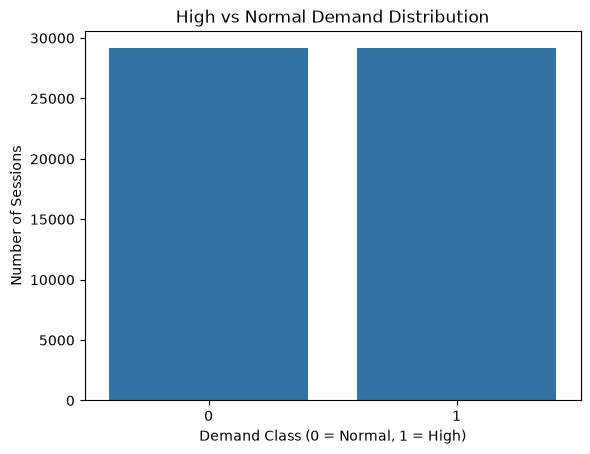

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=y_train_cls)

plt.title("High vs Normal Demand Distribution")
plt.xlabel("Demand Class (0 = Normal, 1 = High)")
plt.ylabel("Number of Sessions")
plt.show()

In [14]:
import joblib

x_train.to_csv("../data/X_train.csv", index=False)
x_test.to_csv("../data/X_test.csv", index=False)

y_train.to_csv("../data/y_train_reg.csv", index=False)
y_test.to_csv("../data/y_test_reg.csv", index=False)

y_train_cls.to_csv("../data/y_train_cls.csv", index=False)
y_test_cls.to_csv("../data/y_test_cls.csv", index=False)

joblib.dump(
    preprocessor,
    "../trained_models/preprocessor.pkl"
)

joblib.dump(
    demand_threshold,
    "../trained_models/demand_threshold.pkl"
)

print("ML data preparation completed.")

ML data preparation completed.
